# Modelo 2 - Clasificación Multiclase: predicción del nivel de riesgo académico

El objetivo de este modelo es clasificar a los estudiantes en **cuatro niveles de riesgo académico**:
- **1: Sin riesgo (G3 >= 14)**
- **2: Riesgo bajo (12 <= G3 < 14)** 
- **3: Riesgo medio (10 <= G3 < 12)** 
- **4: Riesgo alto (G3 < 10)** 

### Lineamientos de implementación:
- **POO y herencia:** Utiliza la clase base `ModeloBase` (`src/train/utils.py`) y la clase hija `ModeloClasificacion` (`src/train/model2.py`).
- **Regla contra Data Leakage:** Las variables G3 y Nivel de Riesgo  **NUNCA** se incluyen en las entradas (X).
- **Estructura de la red:** Salida con activación `softmax` (4 neuronas), función de pérdida `categorical_crossentropy` (con One-Hot Encoding en y) y métricas de clasificación (`accuracy`, `classification_report`, `confusion_matrix`).
- **Comparación:** Se evalúa la **Versión A** (con notas parciales G1, G2 y promedio) frente a la **Versión B** (sin notas parciales, para alerta temprana pura), ambas con y sin `Dropout`.

# 1.Importación librerías

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..') # para poder importar la carpeta src desde notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.train.model2 import ModeloClasificacion, plot_confusion_matrix
from sklearn.metrics import classification_report, confusion_matrix

print('Librerías importadas correctamente')


Librerías importadas correctamente


# 2.Importación fuente de datos

In [2]:
# Lectura de los datos ya limpios y procesados en 02_Preprocesamiento
train = pd.read_csv(config.RUTA_PROCESSED / 'train.csv')
test = pd.read_csv(config.RUTA_PROCESSED / 'test.csv')

In [3]:
train.shape, test.shape

((835, 64), (209, 64))

In [4]:
train.head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes,materia_matematicas,materia_portugues,G3,nivel_riesgo
0,16,3,3,1,2,0,4,3,2,1,...,0,1,1,0,1,0,0,1,13,2
1,15,3,2,1,2,0,4,2,2,1,...,0,1,0,1,1,0,1,0,19,1
2,16,4,3,1,2,0,5,4,2,1,...,0,1,0,1,1,0,0,1,13,2
3,16,2,3,1,2,0,2,3,1,1,...,0,1,0,1,1,0,0,1,14,1
4,17,1,1,3,1,1,5,2,1,1,...,0,1,0,1,0,1,1,0,0,4


### Distribución de las clases de riesgo

In [5]:
# Distribución del nivel de riesgo en train y test
dist_train = train['nivel_riesgo'].value_counts().sort_index()
dist_test = test['nivel_riesgo'].value_counts().sort_index()

dist_df = pd.DataFrame({
    'Etiqueta': ['1: Sin riesgo', '2: Riesgo bajo', '3: Riesgo medio', '4: Riesgo alto'],
    'Train (cant)': dist_train.values,
    'Train (%)': (dist_train.values / len(train) * 100).round(2),
    'Test (cant)': dist_test.values,
    'Test (%)': (dist_test.values / len(test) * 100).round(2)
})
dist_df

,Etiqueta,Train (cant),Train (%),Test (cant),Test (%)
0,1: Sin riesgo,244,29.22,50,23.92
1,2: Riesgo bajo,174,20.84,42,20.10
2,3: Riesgo medio,248,29.70,56,26.79
3,4: Riesgo alto,169,20.24,61,29.19


# 3.Preparación de variables

## 3.1 Versión A: con notas parciales (G1 y G2)
Incluye todas las variables demográficas, socioeconómicas y las notas de los primeros periodos (G1, G2 y `promedio_notas`). Se excluyen estrictamente G3 y nivel\_riesgo de las entradas.

In [6]:
# Instanciamos los objetos de la Versión A (con y sin Dropout)
modelo_A = ModeloClasificacion(version='A', usar_dropout=False)
modelo_A_drop = ModeloClasificacion(version='A', usar_dropout=True)

# preparar_datos() separa X e y, escala con MinMaxScaler (ajustado SOLO en train)
# y convierte y_train a One-Hot para categorical_crossentropy
X_train_A, X_test_A, y_train_cat_A, y_test = modelo_A.preparar_datos(train, test)
_, _, _, _ = modelo_A_drop.preparar_datos(train, test)

## 3.2 Versión B: sin notas parciales (alerta temprana real)
Excluye G1, G2 y `promedio_notas` (además de G3 y nivel\_riesgo). Representa el escenario donde la institución busca detectar estudiantes en riesgo antes de conocer sus calificaciones de exámenes parciales.

In [7]:
# Instanciamos los objetos de la Versión B (con y sin Dropout)
modelo_B = ModeloClasificacion(version='B', usar_dropout=False)
modelo_B_drop = ModeloClasificacion(version='B', usar_dropout=True)

X_train_B, X_test_B, y_train_cat_B, _ = modelo_B.preparar_datos(train, test)
_, _, _, _ = modelo_B_drop.preparar_datos(train, test)

# 4.Escalado y codificación de salidas

El escalado es realizado automáticamente por el método `preparar_datos()` de `ModeloBase`: cada versión ajusta su propio `MinMaxScaler` con `train` y lo aplica a `test`. Comprobamos los rangos y la codificación One-Hot de y.

In [8]:
print(f'Versión A - Entradas: {X_train_A.shape[1]} columnas | Rango: [{X_train_A.min():.2f}, {X_train_A.max():.2f}]')
print(f'Versión B - Entradas: {X_train_B.shape[1]} columnas | Rango: [{X_train_B.min():.2f}, {X_train_B.max():.2f}]')
print(f'y_train One-Hot shape: {y_train_cat_A.shape}')
print('Primeras 3 filas de y_train One-Hot:')
print(y_train_cat_A[:3])

Versión A - Entradas: 62 columnas | Rango: [0.00, 1.00]
Versión B - Entradas: 59 columnas | Rango: [0.00, 1.00]
y_train One-Hot shape: (835, 4)
Primeras 3 filas de y_train One-Hot:
[[0 1 0 0]
 [1 0 0 0]
 [0 1 0 0]]


# 5.Creación del modelo

**Justificación de la arquitectura multiclase:**
- **Capa de entrada:** Cantidad de neuronas igual al número de variables predictoras (62 en Versión A, 59 en Versión B).
- **Capa intermedia:** La mitad de neuronas de la capa anterior, con activación ReLU.
- **Dropout opcional:** Tasa del 20% (0.2) para reducir el sobreajuste y mejorar la generalización.
- **Capa de salida:** 4 neuronas (una por clase de riesgo) con función de activación **softmax**.
- **Compilación:** Función de pérdida `categorical_crossentropy`, optimizador `Adam` con `learning_rate=0.0004` y métrica `accuracy`.

In [9]:
# Inspección de la arquitectura mediante el método crear()
modelo_prueba = ModeloClasificacion(version='A', usar_dropout=True)
modelo_prueba.crear(X_train_A.shape[1])
modelo_prueba.modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

# 6.Entrenamiento y Visualización Separada del Modelo

### ¿Cómo interpretar las dos gráficas de entrenamiento?

Para un análisis riguroso y claro, separamos las métricas en dos gráficos independientes:

1. **Curva de Pérdida (`loss` vs `val_loss`):**
   - **Qué mide:** El error numérico cometido por el modelo al calcular las probabilidades de riesgo.
   - **Comportamiento esperado:** Debe ir **de ARRIBA hacia ABAJO buscando el 0**. Cuanto más baja sea la curva, mejor está aprendiendo la red.
   - **Detección de sobreajuste (overfitting):** La curva azul (`loss`) mide el error en los datos de entrenamiento; la curva naranja (`val_loss`) mide el error en los datos de validación. Si `loss` sigue bajando pero `val_loss` empieza a subir, la red está memorizando en vez de generalizar. En ese punto, el callback `EarlyStopping` detiene el proceso y restaura los pesos del punto más bajo (`restore_best_weights=True`).

2. **Curva de Precisión (`accuracy` vs `val_accuracy`):**
   - **Qué mide:** El porcentaje de aciertos de clasificación (de 0.0 a 1.0, correspondiente a 0% a 100%).
   - **Comportamiento esperado:** Debe ir **de ABAJO hacia ARRIBA buscando el 1.0 (100%)**. Cuanto más alta sea la curva, mayor porcentaje de aciertos tiene la red.
   - **Estabilidad:** La cercanía entre `accuracy` (entrenamiento) y `val_accuracy` (validación) confirma que el modelo predice con éxito en datos que no formaron parte del ajuste directo.

## 6.1 Versión A sin Dropout

Epoch 93: early stopping
Restoring model weights from the end of the best epoch: 68.


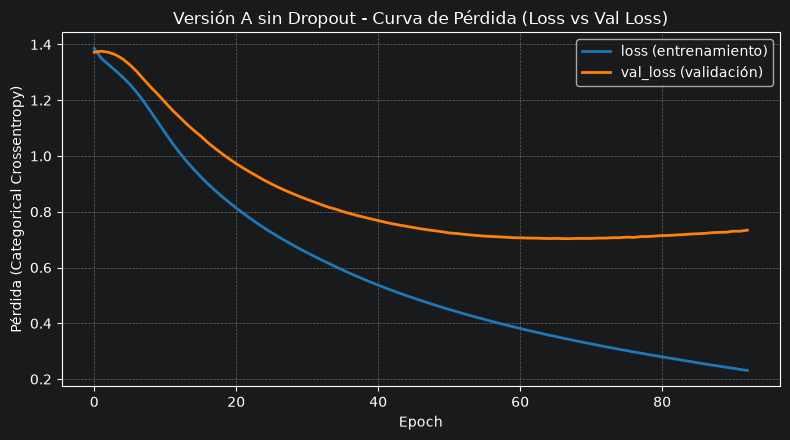

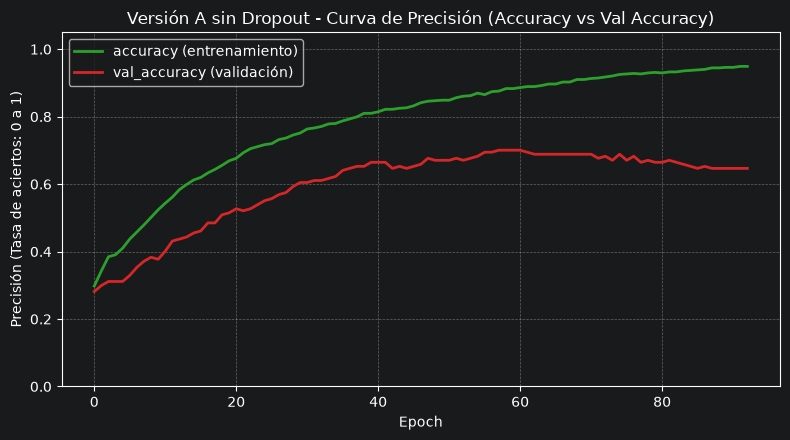

In [10]:
modelo_A.entrenar(X_train_A, y_train_cat_A);
modelo_A.graficar_perdidas()
modelo_A.graficar_precision()


## 6.2 Versión A con Dropout

Epoch 123: early stopping
Restoring model weights from the end of the best epoch: 98.


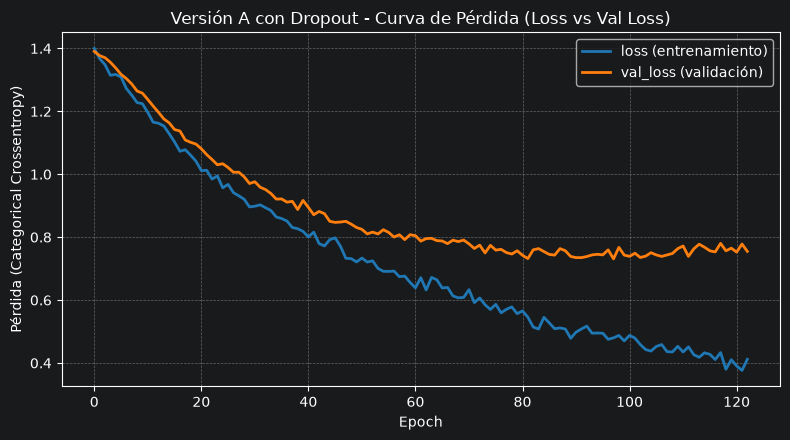

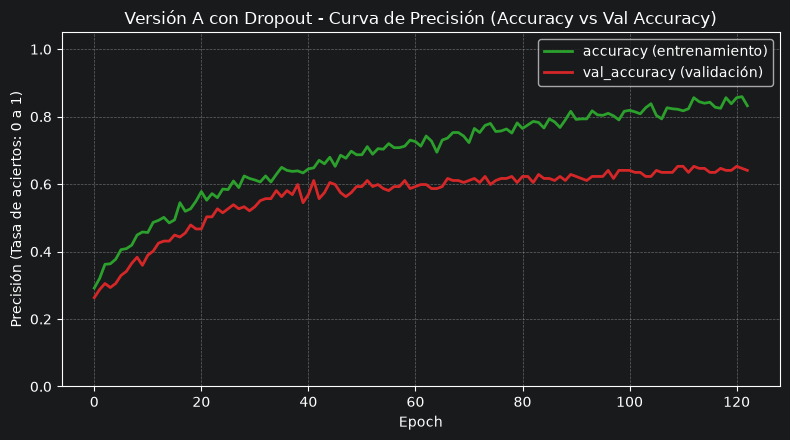

In [11]:
modelo_A_drop.entrenar(X_train_A, y_train_cat_A);
modelo_A_drop.graficar_perdidas()
modelo_A_drop.graficar_precision()


## 6.3 Versión B sin Dropout

Epoch 56: early stopping
Restoring model weights from the end of the best epoch: 31.


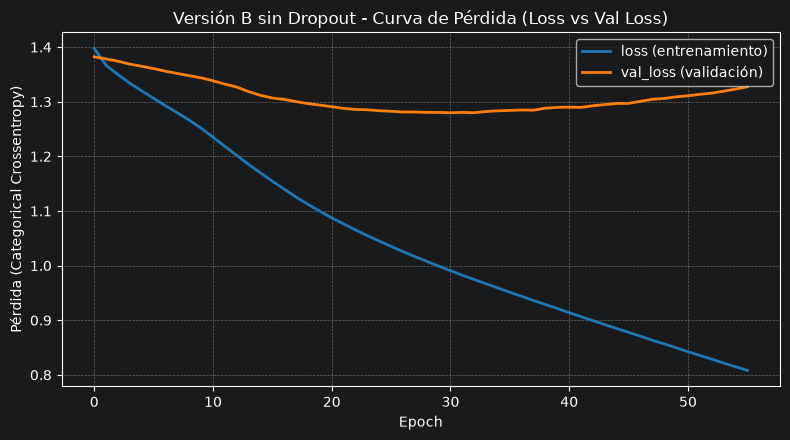

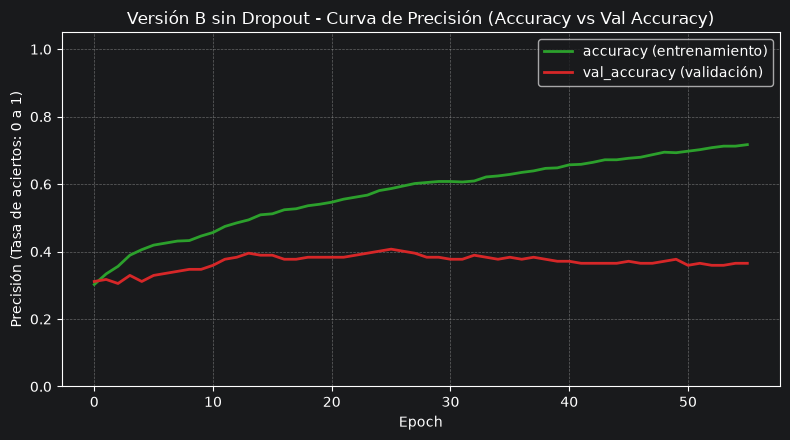

In [12]:
modelo_B.entrenar(X_train_B, y_train_cat_B);
modelo_B.graficar_perdidas()
modelo_B.graficar_precision()


## 6.4 Versión B con Dropout

Epoch 94: early stopping
Restoring model weights from the end of the best epoch: 69.


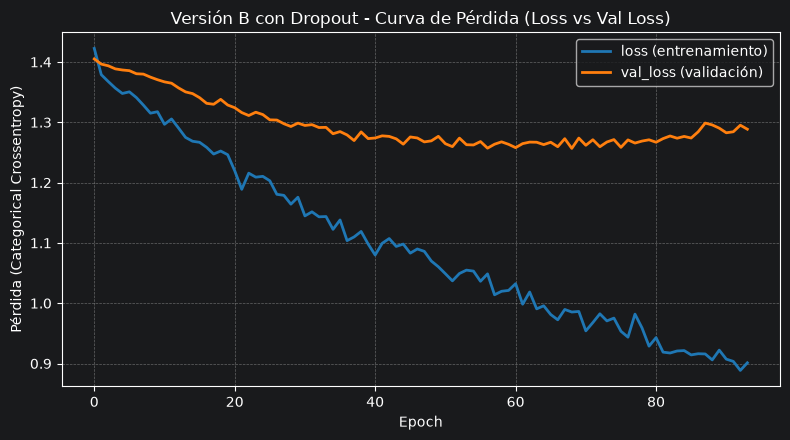

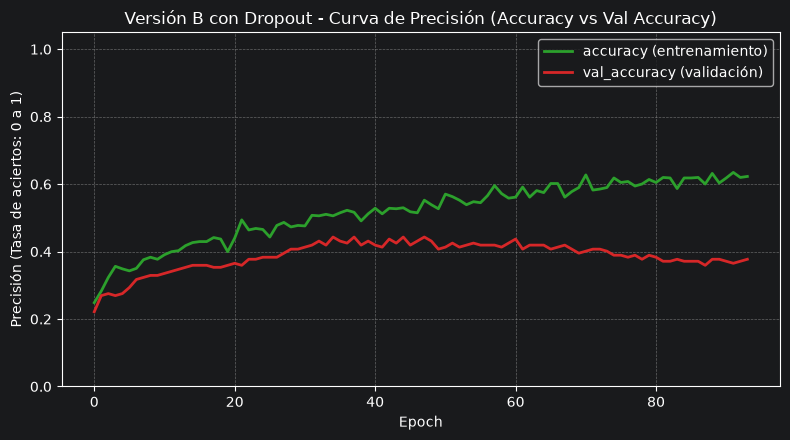

In [13]:
modelo_B_drop.entrenar(X_train_B, y_train_cat_B);
modelo_B_drop.graficar_perdidas()
modelo_B_drop.graficar_precision()


# 7.Evaluación del modelo

Evaluamos el desempeño de cada una de las 4 configuraciones sobre el conjunto de prueba independiente (`test.csv`), calculando Accuracy, Precision ponderada, Recall ponderado y F1-score ponderado.

In [14]:
eval_A = modelo_A.evaluar(X_test_A, y_test)
eval_A_drop = modelo_A_drop.evaluar(X_test_A, y_test)
eval_B = modelo_B.evaluar(X_test_B, y_test)
eval_B_drop = modelo_B_drop.evaluar(X_test_B, y_test)

resultados = pd.DataFrame([
    {'Configuración': eval_A['Modelo'], 'Accuracy': eval_A['Accuracy'], 'Precision': eval_A['Precision'], 'Recall': eval_A['Recall'], 'F1': eval_A['F1']},
    {'Configuración': eval_A_drop['Modelo'], 'Accuracy': eval_A_drop['Accuracy'], 'Precision': eval_A_drop['Precision'], 'Recall': eval_A_drop['Recall'], 'F1': eval_A_drop['F1']},
    {'Configuración': eval_B['Modelo'], 'Accuracy': eval_B['Accuracy'], 'Precision': eval_B['Precision'], 'Recall': eval_B['Recall'], 'F1': eval_B['F1']},
    {'Configuración': eval_B_drop['Modelo'], 'Accuracy': eval_B_drop['Accuracy'], 'Precision': eval_B_drop['Precision'], 'Recall': eval_B_drop['Recall'], 'F1': eval_B_drop['F1']}
])
resultados

,Configuración,Accuracy,Precision,Recall,F1
0,Versión A sin Dropout,0.732057,0.736164,0.732057,0.732940
1,Versión A con Dropout,0.679426,0.682686,0.679426,0.679731
2,Versión B sin Dropout,0.416268,0.420061,0.416268,0.392801
3,Versión B con Dropout,0.449761,0.457171,0.449761,0.427219


### Reportes detallados de clasificación (por nivel de riesgo)

In [15]:
for ev in [eval_A, eval_A_drop, eval_B, eval_B_drop]:
    print('=' * 65)
    print(f"{ev['Modelo']}")
    print('=' * 65)
    print(ev['Reporte'])


Versión A sin Dropout
                  precision    recall  f1-score   support

  Sin riesgo (1)       0.78      0.78      0.78        50
 Riesgo bajo (2)       0.57      0.55      0.56        42
Riesgo medio (3)       0.67      0.75      0.71        56
 Riesgo alto (4)       0.88      0.80      0.84        61

        accuracy                           0.73       209
       macro avg       0.72      0.72      0.72       209
    weighted avg       0.74      0.73      0.73       209

Versión A con Dropout
                  precision    recall  f1-score   support

  Sin riesgo (1)       0.76      0.76      0.76        50
 Riesgo bajo (2)       0.51      0.48      0.49        42
Riesgo medio (3)       0.61      0.70      0.65        56
 Riesgo alto (4)       0.80      0.74      0.77        61

        accuracy                           0.68       209
       macro avg       0.67      0.67      0.67       209
    weighted avg       0.68      0.68      0.68       209

Versión B sin Dropout


### Matrices de Confusión
Visualizamos la matriz de confusión de cada configuración utilizando la representación térmica y la función estándar vistas en clase.

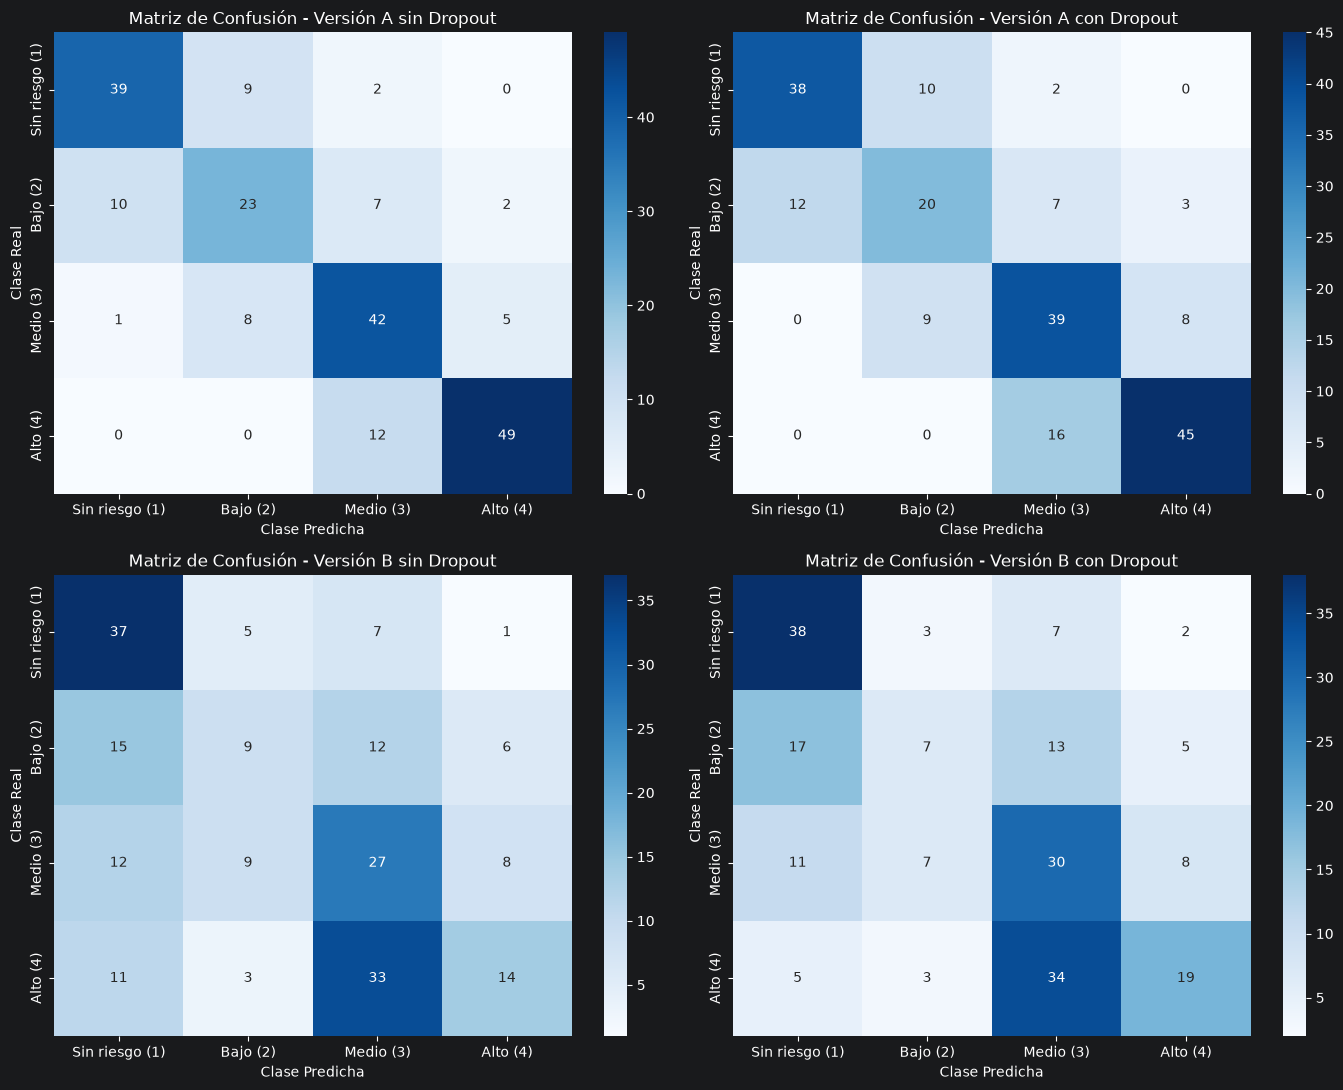

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
modelos_eval = [
    (modelo_A, X_test_A, 'Versión A sin Dropout'),
    (modelo_A_drop, X_test_A, 'Versión A con Dropout'),
    (modelo_B, X_test_B, 'Versión B sin Dropout'),
    (modelo_B_drop, X_test_B, 'Versión B con Dropout')
]

for ax, (m, X, titulo) in zip(axes.ravel(), modelos_eval):
    preds = m.predecir(X)
    cm = confusion_matrix(y_test, preds, labels=m.clases)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Sin riesgo (1)', 'Bajo (2)', 'Medio (3)', 'Alto (4)'],
                yticklabels=['Sin riesgo (1)', 'Bajo (2)', 'Medio (3)', 'Alto (4)'])
    ax.set_title(f'Matriz de Confusión - {titulo}', fontsize=12)
    ax.set_xlabel('Clase Predicha')
    ax.set_ylabel('Clase Real')

plt.tight_layout()
plt.show()

# 8.Comparación y selección del mejor modelo

Comparamos la evolución de la pérdida de validación (`val_loss`) a lo largo del entrenamiento para todas las configuraciones.

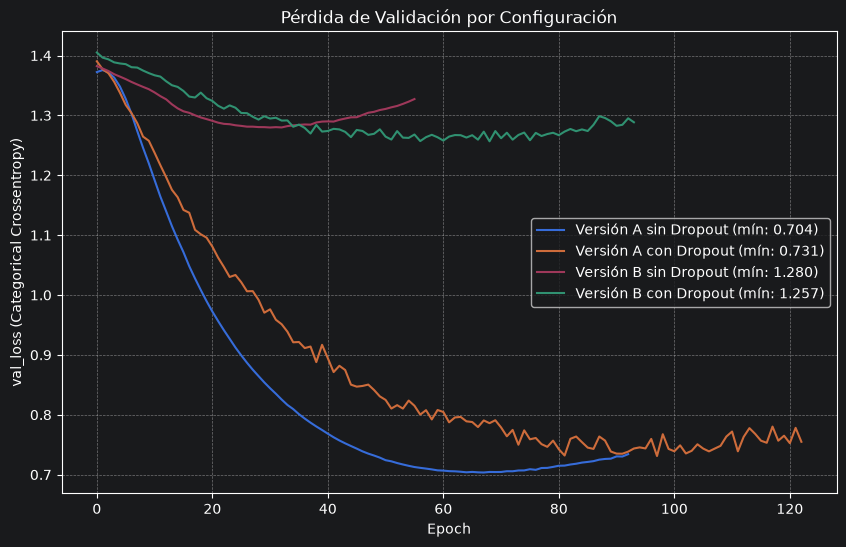

In [17]:
plt.figure(figsize=(10, 6))
for m in [modelo_A, modelo_A_drop, modelo_B, modelo_B_drop]:
    min_loss = m.historial['val_loss'].min()
    plt.plot(m.historial['val_loss'], label=f"{m.nombre} (mín: {min_loss:.3f})")
plt.xlabel('Epoch')
plt.ylabel('val_loss (Categorical Crossentropy)')
plt.title('Pérdida de Validación por Configuración')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Análisis de resultados:
- **Con notas parciales (Versión A):** Alcanza un Accuracy de **73.21%** y un F1 ponderado de **0.7329**. Las clases de riesgo extremo ('Sin riesgo' y 'Riesgo alto') tienen alta precisión y recall, confirmando que las calificaciones previas G1 y G2 son predictores altamente informativos.
- **Sin notas parciales (Versión B - Alerta Temprana):** Alcanza un Accuracy de **44.98%** y F1 de **0.4272**. Al depender exclusivamente de variables demográficas y de contexto, predecir el tramo de notas es más complejo; sin embargo, permite alertar a las autoridades académicas antes del inicio de los exámenes parciales.
- **Selección:** Se selecciona la **Versión A sin Dropout** (Accuracy = 73.21%, F1 = 0.7329) como el modelo principal para clasificar el riesgo académico cuando se dispone de calificaciones de periodos previos.

# 9.Guardar el modelo

Guardamos el modelo seleccionado en la carpeta `models/` con el nombre `model2.keras` mediante el método `guardar()` heredado de `ModeloBase`.

In [20]:
# Guardar el mejor modelo en models/model2.keras
mejor_modelo = modelo_A if eval_A['F1'] >= eval_A_drop['F1'] else modelo_A_drop
print(f'Guardando modelo seleccionado: {mejor_modelo.nombre}')
mejor_modelo.guardar('model2.keras')
print('Modelo guardado exitosamente en models/model2.keras')

Guardando modelo seleccionado: Versión A sin Dropout
Modelo guardado exitosamente en models/model2.keras


In [19]:
from tensorflow.keras.models import load_model

# Cargar el modelo guardado en un objeto nuevo para verificar persistencia e inferencia
modelo_cargado = ModeloClasificacion(version='A', usar_dropout=False)
modelo_cargado.modelo = load_model(config.RUTA_MODELS / 'model2.keras')
modelo_cargado.nombre = 'Modelo cargado'
eval_cargado = modelo_cargado.evaluar(X_test_A, y_test)

print('Verificación del modelo cargado:')
print(f"Accuracy: {eval_cargado['Accuracy']:.4f} | F1: {eval_cargado['F1']:.4f}")

Verificación del modelo cargado:
Accuracy: 0.7321 | F1: 0.7329


**Nota para la API:** El modelo guardado `model2.keras` toma como entrada las 62 variables escaladas con el `scaler.pkl` existente y produce una distribución de probabilidades softmax sobre los 4 niveles de riesgo (1 = Sin riesgo, 2 = Bajo, 3 = Medio, 4 = Alto).